In [2]:
%load_ext autoreload
%autoreload 2

In [13]:
import copy
import random
import time
import math
import numpy as np
import pandas as pd

# Your project imports
from tsn_scheduling_problem import TSNScheduling
from schedule import Schedule, Slot

# Benchmark utilities you already have
from benchmark_utils import (
    build_network_generator_from_usecase,
    generate_one_arrival_stream,
    build_usecase_stream_from_request,
)

# Optional: cleaner printing
np.set_printoptions(suppress=True, linewidth=140)

print("Imports loaded.")

Imports loaded.


In [4]:
CONFIG_PATH = "uc_config.cfg"
INSTANCE_PATH = "finals.json"   # change if you want another instance

problem = TSNScheduling(CONFIG_PATH)
instance = problem.import_scheduling_usecase(INSTANCE_PATH)

# Keep problem aligned with this instance
problem.usecase = instance
problem.build_metadata()

print("Loaded instance:", INSTANCE_PATH)
print("Number of streams in usecase:", len(instance.streams))
print("Number of scheduled slots:", len(instance.schedule))

active_stream_ids = sorted({
    int(slot.stream_id)
    for slot in instance.schedule
    if slot.stream_id is not None
})

print("Active scheduled streams:", len(active_stream_ids))
print("Active stream IDs:", active_stream_ids)
print("Cycle ns:", instance.schedule.cycle_ns)

Loaded instance: finals.json
Number of streams in usecase: 24
Number of scheduled slots: 39
Active scheduled streams: 13
Active stream IDs: [1, 2, 5, 6, 7, 8, 9, 12, 14, 15, 18, 21, 22]
Cycle ns: 500000


In [5]:
from evaluator import TSNConstraintEvaluator, ScheduleEncodingType

def check_schedule_validity(instance, problem, label="schedule"):
    """
    Check whether the current instance.schedule has evaluator violations.
    """
    problem.usecase = instance
    problem.build_metadata()

    evaluator = TSNConstraintEvaluator(
        problem,
        check_routing=False,
        check_task_placement=False,
        scheduling_type=ScheduleEncodingType.START_TIME,
    )

    compact = instance.schedule.to_compact_encoding(
        problem.n_ports,
        problem.n_streams,
    )

    violations = evaluator.per_stream_all_violations(compact)

    breakdown = {
        "seq": int(violations[0].sum()) if violations.shape[0] > 0 else 0,
        "fifo": int(violations[1].sum()) if violations.shape[0] > 1 else 0,
        "macrocycle": int(violations[2].sum()) if violations.shape[0] > 2 else 0,
        "talker_offset": int(violations[3].sum()) if violations.shape[0] > 3 else 0,
        "latency": int(violations[4].sum()) if violations.shape[0] > 4 else 0,
        "total": int(violations.sum()),
    }

    print(f"[{label}] violation breakdown:", breakdown)
    return breakdown

validity = check_schedule_validity(instance, problem, label="initial")

[initial] violation breakdown: {'seq': 0, 'fifo': 0, 'macrocycle': 0, 'talker_offset': 0, 'latency': 0, 'total': 0}


In [6]:
def generate_long_decision_trace(
    instance,
    max_steps=10000,
    lambda_arrival=1.0,
    dt=1.0,
    seed=42,
    ed_ed_settings=None,
):
    """
    Generate a long shared trace for decision-point experiments.

    Each step contains:
      - n_dep = 1 departure opportunity
      - arrivals sampled from Poisson(lambda_arrival * dt)

    The runner decides when to stop based on actual departures.
    """
    rng_np = np.random.default_rng(seed)

    ng = build_network_generator_from_usecase(copy.deepcopy(instance))

    trace = []

    for _ in range(int(max_steps)):
        n_arr = int(rng_np.poisson(lambda_arrival * dt))

        arrivals = []
        for _ in range(n_arr):
            raw_stream = generate_one_arrival_stream(
                ng,
                ed_ed_settings=ed_ed_settings,
            )
            arrivals.append(raw_stream)

        trace.append({
            "n_dep": 1,
            "arrivals": arrivals,
        })

    return trace


In [7]:
def get_active_stream_ids(schedule):
    return sorted({
        int(slot.stream_id)
        for slot in schedule
        if slot.stream_id is not None
    })


def build_port_intervals(schedule):
    relevant_ports = sorted({
        int(slot.port_id)
        for slot in schedule
        if slot.port_id is not None
    })

    return {
        pid: schedule._occupied_intervals_on_port(pid, schedule.cycle_ns)
        for pid in relevant_ports
    }


def init_stream_arrival_times(schedule):
    """
    Initial streams are considered already present at time 0.
    """
    return {
        int(sid): 0.0
        for sid in get_active_stream_ids(schedule)
    }


def summarize_decisions(decisions):
    """
    decisions maps arrival_id -> one of:
      accept, scheduler_reject, raw_none, build_none
    """
    counts = {
        "accept": 0,
        "scheduler_reject": 0,
        "raw_none": 0,
        "build_none": 0,
    }

    for v in decisions.values():
        if v in counts:
            counts[v] += 1
        else:
            counts[v] = counts.get(v, 0) + 1

    return counts


def batch_left_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Clean batch left-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID first-fit-fast.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    # Full backup for rollback
    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    # Check all streams exist and are scheduled
    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    # Remove all selected stream slots together
    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    # Rebuild intervals after batch removal
    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_first_fit_fast(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        # Full rollback
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    # Count real moved streams
    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def full_reconfiguration_preserve_id(
    schedule,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=8,
    beam_width=10,
):
    """
    Full-Reconf-RC baseline.

    It applies right-compaction to all currently active streams.

    This is a full reconfiguration because all active streams are selected
    for removal/reinsertion. The overhead is counted as all selected active
    streams, not only the streams whose offsets changed.
    """

    active_stream_ids = get_active_stream_ids(schedule)
    active_stream_ids = [int(sid) for sid in active_stream_ids]
    attempted_reconfiguration_count = len(active_stream_ids)

    if attempted_reconfiguration_count == 0:
        return {
            "success": False,
            "reason": "no_active_streams",
            "moved_stream_ids": [],
            "reconfigured_stream_ids": [],
            "reconfigured_count": 0,
            "moved_count": 0,
            "failed_stream_ids": [],
            "attempted_reconfiguration_count": 0,
        }

    result = batch_right_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=active_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = [
        int(sid)
        for sid in result.get("moved_stream_ids", [])
    ]

    failed_stream_ids = [
        int(sid)
        for sid in result.get("failed_stream_ids", [])
    ]

    return {
        "success": bool(result.get("success", False)),
        "reason": "ok" if result.get("success", False) else "right_compaction_failed",

        # Streams whose actual offsets changed
        "moved_stream_ids": moved_stream_ids,
        "moved_count": len(moved_stream_ids),

        # Full-Reconf overhead: all active streams selected
        "reconfigured_stream_ids": active_stream_ids,
        "reconfigured_count": attempted_reconfiguration_count,
        "attempted_reconfiguration_count": attempted_reconfiguration_count,

        "failed_stream_ids": failed_stream_ids,

        # useful for debugging
        "raw_result": result,
    }


def batch_right_compact_streams_preserve_id(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=5,
    beam_width=3,
):
    """
    Clean batch right-compaction with preserved stream IDs.

    Steps:
      1. Backup full schedule and stream metadata.
      2. Remove all selected stream slots as a batch.
      3. Reinsert each selected stream using preserve-ID right-fit.
      4. If any stream fails, rollback everything.
      5. Return moved stream IDs.
    """
    import copy

    stream_ids = [int(sid) for sid in stream_ids]

    if not stream_ids:
        return {
            "success": True,
            "moved_stream_ids": [],
            "failed_stream_ids": [],
        }

    old_schedule_slots = copy.deepcopy(list(schedule))
    old_streams = copy.deepcopy(usecase.streams)

    old_offsets = {
        sid: sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )
        for sid in stream_ids
    }

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

        if not old_offsets.get(sid):
            return {
                "success": False,
                "moved_stream_ids": [],
                "failed_stream_ids": [sid],
            }

    selected_set = set(stream_ids)

    schedule[:] = [
        slot for slot in schedule
        if slot.stream_id is None or int(slot.stream_id) not in selected_set
    ]
    schedule.sort()

    if port_intervals is not None:
        port_intervals.clear()
        port_intervals.update(build_port_intervals(schedule))

    problem.usecase = usecase
    problem.build_metadata()

    failed_stream_ids = []

    for sid in stream_ids:
        result = schedule.place_existing_stream_right_fit_backward(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            failed_stream_ids.append(sid)
            break

    if failed_stream_ids:
        schedule[:] = old_schedule_slots
        schedule.sort()

        usecase.streams = old_streams

        problem.usecase = usecase
        problem.build_metadata()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        usecase.removeSchedule()
        _, port_id_to_name = usecase.port_name_id_mapping
        usecase.schedule = schedule
        schedule.update_graph(usecase.graph, port_id_to_name)

        return {
            "success": False,
            "moved_stream_ids": [],
            "failed_stream_ids": failed_stream_ids,
        }

    moved_stream_ids = []

    for sid in stream_ids:
        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if old_offsets.get(sid, []) != new_offsets:
            moved_stream_ids.append(sid)

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": [],
    }


def right_compact_streams_preserve_id_greedy(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=8,
    beam_width=10,
):
    """
    Greedy OF-RC:
    - Try selected streams one by one.
    - Roll back only the stream that fails.
    - Keep successful moves.
    """
    import copy

    moved_stream_ids = []
    failed_stream_ids = []
    tried_stream_ids = []

    stream_ids = [int(sid) for sid in stream_ids]

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            failed_stream_ids.append(sid)
            continue

        old_slots = copy.deepcopy(list(schedule))
        old_streams = copy.deepcopy(usecase.streams)

        old_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if not old_offsets:
            failed_stream_ids.append(sid)
            continue

        tried_stream_ids.append(sid)

        # Remove only this stream
        schedule[:] = [
            slot for slot in schedule
            if slot.stream_id is None or int(slot.stream_id) != sid
        ]
        schedule.sort()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        problem.usecase = usecase
        problem.build_metadata()

        result = schedule.place_existing_stream_right_fit_backward(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            # Roll back only this stream
            schedule[:] = old_slots
            schedule.sort()
            usecase.streams = old_streams

            problem.usecase = usecase
            problem.build_metadata()

            if port_intervals is not None:
                port_intervals.clear()
                port_intervals.update(build_port_intervals(schedule))

            usecase.removeSchedule()
            _, port_id_to_name = usecase.port_name_id_mapping
            usecase.schedule = schedule
            schedule.update_graph(usecase.graph, port_id_to_name)

            failed_stream_ids.append(sid)
            continue

        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if new_offsets != old_offsets:
            moved_stream_ids.append(sid)

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "tried_stream_ids": tried_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": failed_stream_ids,
        "replaced_count": len(moved_stream_ids),
    }


def left_compact_streams_preserve_id_greedy(
    schedule,
    stream_ids,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=8,
    beam_width=10,
):
    """
    Greedy OF-LC:
    - Try selected streams one by one.
    - Remove one stream.
    - Reinsert it using left/first-fit.
    - Keep the move if the new offsets are different.
    - Roll back only the stream that fails.
    """
    import copy

    moved_stream_ids = []
    failed_stream_ids = []
    tried_stream_ids = []

    stream_ids = [int(sid) for sid in stream_ids]

    for sid in stream_ids:
        if sid < 0 or sid >= len(usecase.streams):
            failed_stream_ids.append(sid)
            continue

        old_slots = copy.deepcopy(list(schedule))
        old_streams = copy.deepcopy(usecase.streams)

        old_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if not old_offsets:
            failed_stream_ids.append(sid)
            continue

        tried_stream_ids.append(sid)

        # Remove only this stream from the schedule.
        schedule[:] = [
            slot for slot in schedule
            if slot.stream_id is None or int(slot.stream_id) != sid
        ]
        schedule.sort()

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

        problem.usecase = usecase
        problem.build_metadata()

        # LEFT COMPACTION = first-fit / earliest valid placement.
        result = schedule.place_existing_stream_first_fit_fast(
            stream_id=sid,
            usecase=usecase,
            problem=problem,
            queue_id=queue_id,
            port_intervals=port_intervals,
            max_candidates_per_hop=max_candidates_per_hop,
            beam_width=beam_width,
        )

        if not result.get("accepted"):
            # Roll back only this failed stream.
            schedule[:] = old_slots
            schedule.sort()
            usecase.streams = old_streams

            problem.usecase = usecase
            problem.build_metadata()

            if port_intervals is not None:
                port_intervals.clear()
                port_intervals.update(build_port_intervals(schedule))

            usecase.removeSchedule()
            _, port_id_to_name = usecase.port_name_id_mapping
            usecase.schedule = schedule
            schedule.update_graph(usecase.graph, port_id_to_name)

            failed_stream_ids.append(sid)
            continue

        new_offsets = sorted(
            int(slot.start_ns)
            for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == sid
        )

        if new_offsets != old_offsets:
            moved_stream_ids.append(sid)

        if port_intervals is not None:
            port_intervals.clear()
            port_intervals.update(build_port_intervals(schedule))

    usecase.removeSchedule()
    _, port_id_to_name = usecase.port_name_id_mapping
    usecase.schedule = schedule
    schedule.update_graph(usecase.graph, port_id_to_name)

    return {
        "success": True,
        "tried_stream_ids": tried_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "failed_stream_ids": failed_stream_ids,
        "replaced_count": len(moved_stream_ids),
    }


def oldest_first_left_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    OF-LC(p,n): Oldest-First Left-Compaction with preserved stream IDs.

    Every p departures:
      1. Select n oldest active streams.
      2. Remove them as a batch.
      3. Reinsert them from the left using preserve-ID first-fit-fast.
      4. Roll back if the batch cannot be fully reinserted.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = batch_left_compact_streams_preserve_id(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", []) if result.get("success") else []

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": result.get("success", False),
        "failed_stream_ids": result.get("failed_stream_ids", []),
    }


def oldest_first_right_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=8,
    beam_width=10,
):
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = right_compact_streams_preserve_id_greedy(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", [])

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": True,
        "failed_stream_ids": result.get("failed_stream_ids", []),
        "tried_stream_ids": result.get("tried_stream_ids", []),
    }


def oldest_first_left_compact_defrag_preserve_id(
    schedule,
    usecase,
    problem,
    p,
    n,
    departure_counter,
    queue_id=5,
    port_intervals=None,
    stream_arrival_times=None,
    max_candidates_per_hop=8,
    beam_width=10,
):
    """
    OF-LC:
    Oldest-First Left Compaction.

    Trigger every p departures.
    Select n oldest active streams.
    Try to reinsert each one using earliest/first-fit placement.
    """
    if p <= 0 or n <= 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if departure_counter == 0 or (departure_counter % p) != 0:
        return {
            "triggered": False,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": False,
        }

    if stream_arrival_times is None:
        stream_arrival_times = {}

    active_stream_ids = get_active_stream_ids(schedule)

    if not active_stream_ids:
        return {
            "triggered": True,
            "selected_stream_ids": [],
            "moved_stream_ids": [],
            "replaced_count": 0,
            "success": True,
        }

    stream_first_offset = {}
    for sid in active_stream_ids:
        offsets = get_stream_offsets(schedule, sid)
        stream_first_offset[sid] = min(offsets) if offsets else float("inf")

    ordered_stream_ids = sorted(
        active_stream_ids,
        key=lambda sid: (
            float(stream_arrival_times.get(int(sid), float("inf"))),
            float(stream_first_offset.get(int(sid), float("inf"))),
            int(sid),
        ),
    )

    selected_stream_ids = ordered_stream_ids[:min(int(n), len(ordered_stream_ids))]

    result = left_compact_streams_preserve_id_greedy(
        schedule=schedule,
        stream_ids=selected_stream_ids,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    moved_stream_ids = result.get("moved_stream_ids", [])

    return {
        "triggered": True,
        "selected_stream_ids": selected_stream_ids,
        "moved_stream_ids": moved_stream_ids,
        "replaced_count": len(moved_stream_ids),
        "success": True,
        "failed_stream_ids": result.get("failed_stream_ids", []),
        "tried_stream_ids": result.get("tried_stream_ids", []),
    }


def place_new_stream_with_existing_fast(
    schedule,
    stream,
    usecase,
    problem,
    queue_id=5,
    port_intervals=None,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Place a new arrival stream using the preserve-ID existing-stream placement.

    This replaces schedule.place_stream_first_fit_fast(...).
    """
    import copy

    stream_id = len(usecase.streams)

    # Append new stream definition first, so metadata/evaluator knows it exists
    usecase.streams.append(copy.deepcopy(stream))

    result = schedule.place_existing_stream_first_fit_fast(
        stream_id=stream_id,
        usecase=usecase,
        problem=problem,
        queue_id=queue_id,
        port_intervals=port_intervals,
        max_candidates_per_hop=max_candidates_per_hop,
        beam_width=beam_width,
    )

    if result.get("accepted"):
        return result

    # If rejected, remove the appended stream definition again
    usecase.streams.pop()
    problem.usecase = usecase
    problem.build_metadata()

    return {
        "accepted": [],
        "rejected": [stream_id],
    }


def get_stream_slots(schedule, stream_id):
    return sorted(
        [
            slot for slot in schedule
            if slot.stream_id is not None and int(slot.stream_id) == int(stream_id)
        ],
        key=lambda s: int(s.start_ns),
    )


def get_stream_offsets(schedule, stream_id):
    return [
        int(slot.start_ns)
        for slot in get_stream_slots(schedule, stream_id)
    ]

print("Helper functions loaded.")

Helper functions loaded.


In [8]:
def run_no_defrag_decision_trace(
    instance,
    problem,
    trace,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run No-Defrag on a shared trace.

    Important benchmark semantics:
    - decision_points_per_episode = number of shared trace steps / departure opportunities
    - all methods process the same trace steps and the same arrivals
    - executed departures may differ by method, because a stream can only depart
      if it is active in that method's schedule
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0

    # New clearer counters
    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    decisions = {}

    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                # Trace requested a departure, but this method has no active stream to remove.
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_departures += len(removed_ids)

                # If the trace asked for more removals than actually happened,
                # count the remainder as skipped.
                skipped_departures += max(0, requested_n_dep - len(removed_ids))

        # -------------------------
        # Arrivals after departure
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        # Clear benchmark horizon fields
        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),

        # Keep this old key for compatibility, but it now means executed departures.
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "decisions": decisions,

        "decision_time_s": 0.0,
        "intervention_time_s": 0.0,
        "decision_attempts": 0,
        "intervention_attempts": 0,
        "avg_decision_time_ms": 0.0,
        "avg_intervention_time_ms": 0.0,
    }

In [9]:
def run_of_rc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=8,
    beam_width=10,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0

    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    decision_time_s = 0.0
    intervention_time_s = 0.0
    decision_attempts = 0
    intervention_attempts = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_departures += len(removed_ids)
                skipped_departures += max(0, requested_n_dep - len(removed_ids))

                # Trigger OF-RC every p actually executed departures.
                while (
                    p > 0
                    and n > 0
                    and next_defrag_trigger is not None
                    and executed_departures >= next_defrag_trigger
                ):
                    
                    t0 = time.perf_counter()
                    defrag_result = oldest_first_right_compact_defrag_preserve_id(
                        schedule=sched,
                        usecase=inst,
                        problem=prob,
                        p=1,
                        n=n,
                        departure_counter=1,
                        queue_id=5,
                        port_intervals=port_intervals,
                        stream_arrival_times=stream_arrival_times,
                        max_candidates_per_hop=max_candidates_per_hop,
                        beam_width=beam_width,
                    )
                    elapsed = time.perf_counter() - t0
                    decision_attempts += 1
                    decision_time_s += elapsed
                    intervention_attempts += 1
                    intervention_time_s += elapsed

                    actual_defrag_cycles += 1
                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                    next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,

        "decision_time_s": float(decision_time_s),
        "intervention_time_s": float(intervention_time_s),
        "decision_attempts": int(decision_attempts),
        "intervention_attempts": int(intervention_attempts),
        "avg_decision_time_ms": float(1000.0 * decision_time_s / max(1, decision_attempts)),
        "avg_intervention_time_ms": float(1000.0 * intervention_time_s / max(1, intervention_attempts)),

    }

In [10]:
def run_of_lc_preserve_id_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=8,
    beam_width=10,
):
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0

    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    decision_time_s = 0.0
    intervention_time_s = 0.0
    decision_attempts = 0
    intervention_attempts = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_departures += len(removed_ids)
                skipped_departures += max(0, requested_n_dep - len(removed_ids))

                # Trigger OF-LC every p actually executed departures.
                while (
                    p > 0
                    and n > 0
                    and next_defrag_trigger is not None
                    and executed_departures >= next_defrag_trigger
                ):
                    
                    t0 = time.perf_counter()
                    defrag_result = oldest_first_left_compact_defrag_preserve_id(
                        schedule=sched,
                        usecase=inst,
                        problem=prob,
                        p=1,
                        n=n,
                        departure_counter=1,
                        queue_id=5,
                        port_intervals=port_intervals,
                        stream_arrival_times=stream_arrival_times,
                        max_candidates_per_hop=max_candidates_per_hop,
                        beam_width=beam_width,
                    )
                    elapsed = time.perf_counter() - t0
                    decision_attempts += 1
                    decision_time_s += elapsed
                    intervention_attempts += 1
                    intervention_time_s += elapsed

                    actual_defrag_cycles += 1
                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))
                    else:
                        failed_defrag_cycles += 1

                    next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,

        "decision_time_s": float(decision_time_s),
        "intervention_time_s": float(intervention_time_s),
        "decision_attempts": int(decision_attempts),
        "intervention_attempts": int(intervention_attempts),
        "avg_decision_time_ms": float(1000.0 * decision_time_s / max(1, decision_attempts)),
        "avg_intervention_time_ms": float(1000.0 * intervention_time_s / max(1, intervention_attempts)),

    }

In [11]:
def run_full_reconf_decision_trace(
    instance,
    problem,
    trace,
    p=5,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=8,
    beam_width=10,
):
    """
    Full-Reconf benchmark.

    Every p executed departures:
    - remove all active streams,
    - reinsert them from scratch,
    - count all active streams as reconfigured overhead.
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0

    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    successful_defrag_cycles = 0
    failed_defrag_cycles = 0
    actual_reallocations = 0

    decision_time_s = 0.0
    intervention_time_s = 0.0
    decision_attempts = 0
    intervention_attempts = 0

    next_defrag_trigger = int(p) if p > 0 else None

    decisions = {}

    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_departures += len(removed_ids)
                skipped_departures += max(0, requested_n_dep - len(removed_ids))

                # Trigger full reconfiguration every p executed departures.
                while (
                    p > 0
                    and next_defrag_trigger is not None
                    and executed_departures >= next_defrag_trigger
                ):
                    active_before_reconf = get_active_stream_ids(sched)

                    if len(active_before_reconf) == 0:
                        next_defrag_trigger += int(p)
                        continue

                    t0 = time.perf_counter()

                    defrag_result = full_reconfiguration_preserve_id(
                        schedule=sched,
                        usecase=inst,
                        problem=prob,
                        queue_id=5,
                        port_intervals=port_intervals,
                        stream_arrival_times=stream_arrival_times,
                        max_candidates_per_hop=max_candidates_per_hop,
                        beam_width=beam_width,
                    )

                    elapsed = time.perf_counter() - t0

                    decision_attempts += 1
                    decision_time_s += elapsed
                    intervention_attempts += 1
                    intervention_time_s += elapsed

                    actual_defrag_cycles += 1

                    reconf_cost = int (
                        defrag_result.get(
                            "attempted_reconfiguration_count",
                            defrag_result.get("reconfigured_count", 0),
                        )
                    )

                    actual_reallocations += reconf_cost

                    if defrag_result.get("success", False):
                        successful_defrag_cycles += 1
                    else:
                        failed_defrag_cycles += 1

                    next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=2,
                beam_width=1,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),

        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(successful_defrag_cycles),
        "failed_defrag_cycles": int(failed_defrag_cycles),
        "reallocations": int(actual_reallocations),

        "decisions": decisions,

        "decision_time_s": float(decision_time_s),
        "intervention_time_s": float(intervention_time_s),
        "decision_attempts": int(decision_attempts),
        "intervention_attempts": int(intervention_attempts),
        "avg_decision_time_ms": float(1000.0 * decision_time_s / max(1, decision_attempts)),
        "avg_intervention_time_ms": float(1000.0 * intervention_time_s / max(1, intervention_attempts)),
    }

In [12]:
def run_of_ff_decision_trace(
    instance,
    problem,
    trace,
    p=8,
    n=10,
    decision_points_per_episode=100,
    seed=42,
    max_candidates_per_hop=2,
    beam_width=1,
):
    """
    Run OF-FF on a shared trace.

    Benchmark semantics:
    - decision_points_per_episode = number of shared trace steps
    - OF-FF triggers every p actually executed departures
    """
    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    accepted = 0
    rejected = 0
    total_arrivals = 0

    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    next_defrag_trigger = int(p) if p > 0 else None

    decision_time_s = 0.0
    intervention_time_s = 0.0
    decision_attempts = 0
    intervention_attempts = 0

    decisions = {}

    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_departures += len(removed_ids)
                skipped_departures += max(0, requested_n_dep - len(removed_ids))

                # Trigger OF-FF every p actually executed departures.
                while (
                    p > 0
                    and n > 0
                    and next_defrag_trigger is not None
                    and executed_departures >= next_defrag_trigger
                ):
                    t0 = time.perf_counter()
                    defrag_result = sched.oldest_first_first_fit_defrag(
                        usecase=inst,
                        problem=prob,
                        p=1,
                        n=n,
                        departure_counter=1,
                        queue_id=5,
                        port_intervals=port_intervals,
                        stream_arrival_times=stream_arrival_times,
                    )
                    elapsed = time.perf_counter() - t0
                    decision_attempts += 1
                    decision_time_s += elapsed
                    intervention_attempts += 1
                    intervention_time_s += elapsed

                    if defrag_result.get("triggered", False):
                        actual_defrag_cycles += 1
                        actual_reallocations += int(defrag_result.get("replaced_count", 0))

                    next_defrag_trigger += int(p)

        # -------------------------
        # Arrivals after departure/defrag
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)
            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0
    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),
        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),
        "defrag_cycles": int(actual_defrag_cycles),
        "reallocations": int(actual_reallocations),
        "decisions": decisions,

        "decision_time_s": float(decision_time_s),
        "intervention_time_s": float(intervention_time_s),
        "decision_attempts": int(decision_attempts),
        "intervention_attempts": int(intervention_attempts),
        "avg_decision_time_ms": float(1000.0 * decision_time_s / max(1, decision_attempts)),
        "avg_intervention_time_ms": float(1000.0 * intervention_time_s / max(1, intervention_attempts)),
    
    }

In [55]:
from stable_baselines3 import DQN
from env import TSNCandidatePathEnv
import torch

def run_drl_decision_trace(
    instance,
    problem,
    trace,
    model_path,
    decision_points_per_episode=300,
    ed_ed_settings=None,
    seed=42,

    # Arrival scheduler params
    max_candidates_per_hop=8,
    beam_width=10,

    # DRL/env params
    drl_cfg=None,
    deterministic=True,
    max_actions_per_decision=100,
    debug=False,
    debug_max_decisions=3,
):
    drl_cfg = drl_cfg

    rng_py = random.Random(seed)

    inst = copy.deepcopy(instance)
    prob = copy.deepcopy(problem)
    prob.usecase = inst
    prob.build_metadata()

    sched = inst.schedule
    port_intervals = build_port_intervals(sched)
    stream_arrival_times = init_stream_arrival_times(sched)

    model = DQN.load(model_path)

    env = TSNCandidatePathEnv(
        problem=copy.deepcopy(prob),
        usecase=copy.deepcopy(inst),
        useless_gap_threshold_bytes=drl_cfg["useless_gap_threshold_bytes"],
        expected_incoming_bytes=drl_cfg["expected_incoming_bytes"],
        invalid_penalty=drl_cfg["invalid_penalty"],
        max_candidates=drl_cfg["max_candidates"],
        max_steps=drl_cfg["max_steps"],
        max_hops=drl_cfg["max_hops"],
        init_from_usecase_schedule=drl_cfg["init_from_usecase_schedule"],
        include_current_offset_candidate=drl_cfg["include_current_offset_candidate"],
        per_hop_candidate_limit=drl_cfg["per_hop_candidate_limit"],
        beam_width=drl_cfg["beam_width"],
        defrag_cycle_penalty=drl_cfg["defrag_cycle_penalty"],
        reallocation_penalty=drl_cfg["reallocation_penalty"],
        lambda_arrival=0.0,
        mu_departure=0.0,
        dt=1.0,
        decision_points_per_episode=decision_points_per_episode,
        top_k_oldest_random=drl_cfg["top_k_oldest_random"],
        seed=seed,
        ed_ed_settings=ed_ed_settings,
        reward_alpha=drl_cfg.get("reward_alpha", 0.90),
        min_reallocations_per_cycle=drl_cfg.get("min_reallocations_per_cycle", 1),
        early_stop_penalty=drl_cfg.get("early_stop_penalty", 0.0),
        stream_cooldown_decisions=drl_cfg.get("stream_cooldown_decisions", 5),
    )

    accepted = 0
    rejected = 0
    total_arrivals = 0

    trace_steps = 0
    departure_attempts = 0
    requested_departures = 0
    executed_departures = 0
    skipped_departures = 0

    raw_none_rejected = 0
    build_none_rejected = 0
    scheduler_rejected = 0

    actual_defrag_cycles = 0
    actual_reallocations = 0
    invalid_moves = 0

    decision_time_s = 0.0
    intervention_time_s = 0.0
    decision_attempts = 0
    intervention_attempts = 0

    decisions = {}
    debug_decisions_seen = 0

    def sync_env_from_current_schedule():
        """
        Sync DRL env with the externally controlled benchmark state.
        """
        env.usecase = inst
        env.problem = prob
        env.problem.usecase = inst
        env.problem.build_metadata()
        env._rebuild_runtime_metadata()

        env._load_state_from_schedule(sched)
        env.usecase.schedule = sched
        env.port_intervals = build_port_intervals(sched)

        env.stream_arrival_times = dict(stream_arrival_times)
        env.current_time = float(trace_steps)
        env.in_defrag_cycle = False
        env.decision_active = False
        env.current_candidates = []

    def run_one_drl_decision():
        nonlocal actual_defrag_cycles
        nonlocal actual_reallocations
        nonlocal invalid_moves
        nonlocal debug_decisions_seen

        moved_this_decision = False

        sync_env_from_current_schedule()

        active = env._active_stream_ids()
        if not active:
            return False

        env.decision_stream_order = env._ordered_streams_by_age()
        env.decision_pointer = 0

        if not env.decision_stream_order:
            return False

        env.focus.stream_id = int(env.decision_stream_order[0])
        env.current_candidates = env._candidate_list_for_stream(
            int(env.focus.stream_id)
        )
        env.decision_active = True
        env.in_defrag_cycle = False

        if debug and debug_decisions_seen < debug_max_decisions:
            print("\n[DRL decision]")
            print("Active streams:", len(active))
            print("Decision order:", env.decision_stream_order[:10])

        for action_step in range(max_actions_per_decision):
            obs = env._get_obs()
            action, _ = model.predict(obs, deterministic=deterministic)

            if debug and debug_decisions_seen < debug_max_decisions:
                obs_tensor, _ = model.policy.obs_to_tensor(obs)

                with torch.no_grad():
                    q_values = model.q_net(obs_tensor)
                    q_values = q_values.cpu().numpy().flatten()

                valid_mask = obs["candidate_mask"].astype(bool)

                print("  Q-values:")
                for a_idx, q in enumerate(q_values):
                    valid_txt = "valid" if valid_mask[a_idx] else "pad"
                    name = "STOP" if a_idx == 0 else f"CAND {a_idx - 1}"
                    print(f"    action {a_idx} ({name:6s}, {valid_txt}) Q={q:.4f}")

            action = int(np.asarray(action).item())

            # padded/non-existing candidate => STOP
            if action > 0:
                cand_idx = action - 1
                if cand_idx < 0 or cand_idx >= len(env.current_candidates):
                    action = 0

            if debug and debug_decisions_seen < debug_max_decisions:
                print(
                    f"  focus={env.focus.stream_id}, "
                    f"cands={len(env.current_candidates)}, "
                    f"action={action}"
                )

            # STOP
            if action == 0:
                break

            cand = env.current_candidates[action - 1]

            saved_ports = copy.deepcopy(env.port_schedules)
            saved_offsets = copy.deepcopy(env.stream_offsets)

            applied = env._apply_stream_move(
                cand.stream_id,
                cand.offsets,
            )

            if not applied:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            violation_sum = env._violation_sum()

            if violation_sum != 0:
                invalid_moves += 1
                env.port_schedules = saved_ports
                env.stream_offsets = saved_offsets
                env._sync_usecase_schedule()
                env._sync_evaluator_with_schedule_durations()
                break

            # Valid move
            if not env.in_defrag_cycle:
                env.in_defrag_cycle = True
                actual_defrag_cycles += 1

            actual_reallocations += 1
            moved_this_decision = True

            env._backup_current_as_last_valid()
            env._advance_stream_focus()

            if env.decision_pointer >= len(env.decision_stream_order):
                break

            env.current_candidates = env._candidate_list_for_stream(
                int(env.focus.stream_id)
            )

            if not env.current_candidates:
                env._advance_stream_focus()
                if env.decision_pointer >= len(env.decision_stream_order):
                    break

                env.current_candidates = env._candidate_list_for_stream(
                    int(env.focus.stream_id)
                )

        # Commit only if a move occurred
        if moved_this_decision:
            new_sched = env.get_combined_schedule()
            sched[:] = list(new_sched)
            sched.sort()

            inst.schedule = sched
            port_intervals.clear()
            port_intervals.update(build_port_intervals(sched))

        debug_decisions_seen += 1
        return bool(moved_this_decision)

    # IMPORTANT:
    # This loop must be OUTSIDE run_one_drl_decision().
    for step in trace[: int(decision_points_per_episode)]:
        trace_steps += 1

        # -------------------------
        # Departure opportunity
        # -------------------------
        requested_n_dep = int(step.get("n_dep", 0))
        requested_departures += requested_n_dep

        executed_this_step = 0

        if requested_n_dep > 0:
            departure_attempts += 1

            active_ids = get_active_stream_ids(sched)
            n_active = len(active_ids)
            n_dep = min(requested_n_dep, n_active)

            if n_dep <= 0:
                skipped_departures += requested_n_dep
            else:
                del_result = sched.delete_streams(
                    n_remove=n_dep,
                    usecase=inst,
                    rng=rng_py,
                    port_intervals=port_intervals,
                    stream_arrival_times=stream_arrival_times,
                )

                removed_ids = [
                    int(sid)
                    for sid in del_result.get("removed_stream_ids", [])
                ]

                for sid in removed_ids:
                    stream_arrival_times.pop(int(sid), None)

                executed_this_step = len(removed_ids)
                executed_departures += executed_this_step
                skipped_departures += max(0, requested_n_dep - executed_this_step)

                # DRL decision only after an actually executed departure.
                if executed_this_step > 0:
                    t0 = time.perf_counter()
                    moved = run_one_drl_decision()
                    elapsed = time.perf_counter() - t0
                    decision_attempts += 1
                    decision_time_s += elapsed
                    if moved:
                        intervention_attempts += 1
                        intervention_time_s += elapsed

        # -------------------------
        # Arrivals
        # -------------------------
        for raw_stream in step.get("arrivals", []):
            total_arrivals += 1
            arrival_id = total_arrivals

            if raw_stream is None:
                rejected += 1
                raw_none_rejected += 1
                decisions[arrival_id] = "raw_none"
                continue

            stream_id = len(inst.streams)

            stream = build_usecase_stream_from_request(
                raw_stream,
                stream_id,
                inst,
                k_paths=1,
            )

            if stream is None:
                rejected += 1
                build_none_rejected += 1
                decisions[arrival_id] = "build_none"
                continue

            result = place_new_stream_with_existing_fast(
                schedule=sched,
                stream=stream,
                usecase=inst,
                problem=prob,
                port_intervals=port_intervals,
                max_candidates_per_hop=max_candidates_per_hop,
                beam_width=beam_width,
            )

            if result.get("accepted"):
                accepted += 1
                new_sid = int(result["accepted"][-1])
                stream_arrival_times[new_sid] = float(trace_steps)
                decisions[arrival_id] = "accept"
            else:
                rejected += 1
                scheduler_rejected += 1
                decisions[arrival_id] = "scheduler_reject"

    sbr = rejected / total_arrivals if total_arrivals > 0 else 0.0
    acc = accepted / total_arrivals if total_arrivals > 0 else 0.0

    scheduler_attempts = accepted + scheduler_rejected
    scheduler_sbr = scheduler_rejected / scheduler_attempts if scheduler_attempts > 0 else 0.0

    return {
        "sbr": float(sbr),
        "acceptance": float(acc),
        "scheduler_sbr": float(scheduler_sbr),

        "steps": int(trace_steps),
        "trace_steps": int(trace_steps),
        "departure_attempts": int(departure_attempts),
        "requested_departures": int(requested_departures),
        "executed_departures": int(executed_departures),
        "skipped_departures": int(skipped_departures),

        # Backward compatibility: this now means executed departures.
        "departures": int(executed_departures),

        "accepted": int(accepted),
        "rejected": int(rejected),
        "arrivals": int(total_arrivals),

        "raw_none_rejected": int(raw_none_rejected),
        "build_none_rejected": int(build_none_rejected),
        "scheduler_rejected": int(scheduler_rejected),
        "scheduler_attempts": int(scheduler_attempts),

        "defrag_cycles": int(actual_defrag_cycles),
        "successful_defrag_cycles": int(actual_defrag_cycles),
        "failed_defrag_cycles": 0,
        "reallocations": int(actual_reallocations),
        "invalid_moves": int(invalid_moves),

        "decisions": decisions,

        "decision_time_s": float(decision_time_s),
        "intervention_time_s": float(intervention_time_s),
        "decision_attempts": int(decision_attempts),
        "intervention_attempts": int(intervention_attempts),
        "avg_decision_time_ms": float(1000.0 * decision_time_s / max(1, decision_attempts)),
        "avg_intervention_time_ms": float(1000.0 * intervention_time_s / max(1, intervention_attempts)),

    }

In [14]:
def compare_decision_dicts(no_decisions, of_decisions):
    """
    Compare per-arrival decisions between No-Defrag and OF-FF.

    We treat only 'accept' as accepted.
    Everything else is rejected.
    """
    all_ids = sorted(set(no_decisions.keys()) | set(of_decisions.keys()))

    both_accept = []
    both_reject = []
    of_gain = []
    of_damage = []
    missing = []

    for aid in all_ids:
        if aid not in no_decisions or aid not in of_decisions:
            missing.append(aid)
            continue

        no_acc = no_decisions[aid] == "accept"
        of_acc = of_decisions[aid] == "accept"

        if no_acc and of_acc:
            both_accept.append(aid)
        elif (not no_acc) and (not of_acc):
            both_reject.append(aid)
        elif (not no_acc) and of_acc:
            of_gain.append(aid)
        elif no_acc and (not of_acc):
            of_damage.append(aid)

    summary = {
        "both_accept": both_accept,
        "both_reject": both_reject,
        "of_gain": of_gain,
        "of_damage": of_damage,
        "missing": missing,
        "net_gain": len(of_gain) - len(of_damage),
    }

    print(f"Both accept: {len(both_accept)}")
    print(f"Both reject: {len(both_reject)}")
    print(f"OF gain    : {len(of_gain)} {of_gain[:30]}")
    print(f"OF damage  : {len(of_damage)} {of_damage[:30]}")
    print(f"Missing    : {len(missing)}")
    print(f"Net gain   : {summary['net_gain']}")

    return summary


In [15]:
def benchmark_decision_methods(
    instance,
    problem,
    methods=("no_defrag", "of_ff", "of_rc", "of_lc", "full_reconf", "drl"),
    n_episodes=10,
    decision_points_per_episode=300,
    lambda_arrival=0.75,
    seed=42,
    max_steps=50000,

    # Arrival scheduler params
    arrival_max_candidates_per_hop=2,
    arrival_beam_width=1,

    # OF-FF params
    of_ff_p=8,
    of_ff_n=10,
    of_ff_max_candidates_per_hop=2,
    of_ff_beam_width=1,

    # OF-FF second params
    of_ff2_p=5,
    of_ff2_n=15,
    of_ff2_max_candidates_per_hop=2,
    of_ff2_beam_width=1,

    # OF-RC params
    of_rc_p=5,
    of_rc_n=10,
    of_rc_max_candidates_per_hop=2,
    of_rc_beam_width=1,

    # OF-RC second params
    of_rc2_p=8,
    of_rc2_n=10,
    of_rc2_max_candidates_per_hop=2,
    of_rc2_beam_width=1,

    # OF-LC params
    of_lc_p=8,
    of_lc_n=10,
    of_lc_max_candidates_per_hop=2,
    of_lc_beam_width=1,

    # Full Reconf params
    full_reconf_p=5,
    full_reconf_max_candidates_per_hop=8,
    full_reconf_beam_width=10,

    # DRL params
    drl_model_path=None,
    drl_cfg=None,
    drl_deterministic=True,
    drl_max_actions_per_decision=3,
    drl_max_candidates_per_hop=2,
    drl_beam_width=1,
    drl_debug=False,

    # DRL second model/cfg
    drl2_model_path=None,
    drl2_cfg=None,
    drl2_deterministic=True,
    drl2_max_actions_per_decision=3,
    drl2_max_candidates_per_hop=2,
    drl2_beam_width=1,
    drl2_debug=False,

    # Optional debug
    compare_to_no=True,
    verbose=True,
    ed_ed_settings=None,
):
    """
    Flexible shared-trace decision-point benchmark.

    Supported methods:
      - "no_defrag"
      - "of_ff"
      - "of_ff2"
      - "of_rc"
      - "of_rc2"
      - "of_lc"
      - "full_reconf"
      - "drl"
      - "drl2"
    """

    valid_methods = {
        "no_defrag",
        "of_ff",
        "of_ff2",
        "of_rc",
        "of_rc2",
        "of_lc",
        "full_reconf",
        "drl",
        "drl2",
    }

    methods = tuple(methods)

    unknown = set(methods) - valid_methods
    if unknown:
        raise ValueError(f"Unknown methods: {unknown}. Valid methods: {valid_methods}")

    if compare_to_no and "no_defrag" not in methods:
        raise ValueError("compare_to_no=True requires 'no_defrag' in methods.")

    if "drl" in methods:
        if drl_model_path is None:
            raise ValueError("methods includes 'drl', but drl_model_path is None.")
        if drl_cfg is None:
            raise ValueError("methods includes 'drl', but drl_cfg is None.")

    if "drl2" in methods:
        if drl2_model_path is None:
            raise ValueError("methods includes 'drl2', but drl2_model_path is None.")
        if drl2_cfg is None:
            raise ValueError("methods includes 'drl2', but drl2_cfg is None.")

    results = {}

    # Basic arrays for each method
    for m in methods:
        results[f"{m}_sbr"] = []
        results[f"{m}_scheduler_sbr"] = []
        results[f"{m}_acc"] = []
        results[f"{m}_arrivals"] = []
        results[f"{m}_departures"] = []
        results[f"{m}_scheduler_rejected"] = []
        results[f"{m}_decisions"] = []

        # Overhead arrays
        results[f"{m}_reallocations"] = []
        results[f"{m}_defrag_cycles"] = []
        results[f"{m}_successful_defrag_cycles"] = []
        results[f"{m}_failed_defrag_cycles"] = []

        results[f"{m}_trace_steps"] = []
        results[f"{m}_departure_attempts"] = []
        results[f"{m}_requested_departures"] = []
        results[f"{m}_executed_departures"] = []
        results[f"{m}_skipped_departures"] = []

        # Timing arrays
        results[f"{m}_decision_time_s"] = []
        results[f"{m}_intervention_time_s"] = []
        results[f"{m}_decision_attempts"] = []
        results[f"{m}_intervention_attempts"] = []
        results[f"{m}_avg_decision_time_ms"] = []
        results[f"{m}_avg_intervention_time_ms"] = []

        # Comparison arrays
        if m != "no_defrag":
            results[f"{m}_gain"] = []
            results[f"{m}_damage"] = []
            results[f"{m}_net_gain"] = []

    for ep in range(n_episodes):
        ep_seed = seed + ep

        trace = generate_long_decision_trace(
            instance=instance,
            max_steps=max_steps,
            lambda_arrival=lambda_arrival,
            seed=ep_seed,
            ed_ed_settings=ed_ed_settings,
        )

        ep_outputs = {}

        if "no_defrag" in methods:
            ep_outputs["no_defrag"] = run_no_defrag_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=arrival_max_candidates_per_hop,
                beam_width=arrival_beam_width,
            )

        if "of_ff" in methods:
            ep_outputs["of_ff"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff_p,
                n=of_ff_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff_max_candidates_per_hop,
                beam_width=of_ff_beam_width,
            )

        if "of_ff2" in methods:
            ep_outputs["of_ff2"] = run_of_ff_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_ff2_p,
                n=of_ff2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_ff2_max_candidates_per_hop,
                beam_width=of_ff2_beam_width,
            )

        if "of_lc" in methods:
            ep_outputs["of_lc"] = run_of_lc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_lc_p,
                n=of_lc_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_lc_max_candidates_per_hop,
                beam_width=of_lc_beam_width,
            )

        if "of_rc" in methods:
            ep_outputs["of_rc"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc_p,
                n=of_rc_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc_max_candidates_per_hop,
                beam_width=of_rc_beam_width,
            )

        if "of_rc2" in methods:
            ep_outputs["of_rc2"] = run_of_rc_preserve_id_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=of_rc2_p,
                n=of_rc2_n,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=of_rc2_max_candidates_per_hop,
                beam_width=of_rc2_beam_width,
            )

        if "full_reconf" in methods:
            ep_outputs["full_reconf"] = run_full_reconf_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                p=full_reconf_p,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=full_reconf_max_candidates_per_hop,
                beam_width=full_reconf_beam_width,
            )

        if "drl" in methods:
            ep_outputs["drl"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl_max_candidates_per_hop,
                beam_width=drl_beam_width,
                drl_cfg=drl_cfg,
                deterministic=drl_deterministic,
                max_actions_per_decision=drl_max_actions_per_decision,
                debug=drl_debug,
                ed_ed_settings=ed_ed_settings,
            )

        if "drl2" in methods:
            ep_outputs["drl2"] = run_drl_decision_trace(
                instance=instance,
                problem=problem,
                trace=trace,
                model_path=drl2_model_path,
                decision_points_per_episode=decision_points_per_episode,
                seed=ep_seed,
                max_candidates_per_hop=drl2_max_candidates_per_hop,
                beam_width=drl2_beam_width,
                drl_cfg=drl2_cfg,
                deterministic=drl2_deterministic,
                max_actions_per_decision=drl2_max_actions_per_decision,
                debug=drl2_debug,
                ed_ed_settings=ed_ed_settings,
            )


        #sanity check to catch unfairness in comparison (e.g. different arrival sequences)
        arrival_counts = {m: ep_outputs[m]["arrivals"] for m in ep_outputs}
        if len(set(arrival_counts.values())) != 1:
            raise RuntimeError(
                f"Non-shared arrival count in episode {ep}: {arrival_counts}"
            )

        decision_keys = {m: set(ep_outputs[m]["decisions"].keys()) for m in ep_outputs}
        first_m = next(iter(decision_keys))
        for m in decision_keys:
            if decision_keys[m] != decision_keys[first_m]:
                raise RuntimeError(
                    f"Arrival decision IDs differ in episode {ep}: "
                    f"{first_m}={len(decision_keys[first_m])}, {m}={len(decision_keys[m])}"
                )


        # Store outputs
        for m, res in ep_outputs.items():
            results[f"{m}_sbr"].append(res["sbr"])
            results[f"{m}_scheduler_sbr"].append(res.get("scheduler_sbr", res["sbr"]))
            results[f"{m}_acc"].append(res["acceptance"])

            # Shared-arrival benchmark fields
            results[f"{m}_arrivals"].append(res["arrivals"])
            results[f"{m}_trace_steps"].append(res.get("trace_steps", res.get("steps", np.nan)))
            results[f"{m}_departure_attempts"].append(res.get("departure_attempts", np.nan))
            results[f"{m}_requested_departures"].append(res.get("requested_departures", np.nan))
            results[f"{m}_executed_departures"].append(
                res.get("executed_departures", res.get("departures", np.nan))
            )
            results[f"{m}_skipped_departures"].append(res.get("skipped_departures", np.nan))

            # Backward compatibility: departures now means executed departures
            results[f"{m}_departures"].append(
                res.get("executed_departures", res.get("departures", np.nan))
            )

            results[f"{m}_scheduler_rejected"].append(res["scheduler_rejected"])
            results[f"{m}_decisions"].append(res["decisions"])

            results[f"{m}_reallocations"].append(res.get("reallocations", 0))
            results[f"{m}_defrag_cycles"].append(res.get("defrag_cycles", 0))
            results[f"{m}_successful_defrag_cycles"].append(
                res.get("successful_defrag_cycles", res.get("defrag_cycles", 0))
            )
            results[f"{m}_failed_defrag_cycles"].append(
                res.get("failed_defrag_cycles", 0)
            )

            results[f"{m}_decision_time_s"].append(res.get("decision_time_s", 0.0))
            results[f"{m}_intervention_time_s"].append(res.get("intervention_time_s", 0.0))
            results[f"{m}_decision_attempts"].append(res.get("decision_attempts", 0))
            results[f"{m}_intervention_attempts"].append(res.get("intervention_attempts", 0))
            results[f"{m}_avg_decision_time_ms"].append(res.get("avg_decision_time_ms", 0.0))
            results[f"{m}_avg_intervention_time_ms"].append(res.get("avg_intervention_time_ms", 0.0))

        # Compare each method to no_defrag
        if compare_to_no:
            no_decisions = ep_outputs["no_defrag"]["decisions"]

            for m in methods:
                if m == "no_defrag":
                    continue

                cmp_m = compare_decision_dicts(
                    no_decisions,
                    ep_outputs[m]["decisions"],
                )

                results[f"{m}_gain"].append(len(cmp_m["of_gain"]))
                results[f"{m}_damage"].append(len(cmp_m["of_damage"]))
                results[f"{m}_net_gain"].append(cmp_m["net_gain"])

        if verbose:
            msg = [
                f"Ep {ep:02d}",
                f"arr={next(iter(ep_outputs.values()))['arrivals']}",
                f"dep={next(iter(ep_outputs.values()))['departures']}",
            ]

            for m in methods:
                res = ep_outputs[m]
                part = f"{m}={res['sbr']:.4f}"

                if m != "no_defrag" and compare_to_no:
                    part += (
                        f" net={results[f'{m}_net_gain'][-1]}"
                        f" realloc={res.get('reallocations', 0)}"
                    )

                if m in {"of_rc", "of_rc2", "of_ff", "of_ff2", "of_lc", "full_reconf", "drl", "drl2"}:
                    part += f" cycles={res.get('defrag_cycles', 0)}"

                msg.append(part)

            print(" | ".join(msg))

    # Convert to numpy arrays, except decisions
    for k in list(results.keys()):
        if k.endswith("_decisions"):
            continue
        results[k] = np.array(results[k])

    return results

In [11]:
def summarize_decision_methods(results, methods=("no_defrag", "of_ff", "of_rc")):
    rows = []

    def mean_key(key, default=np.nan):
        if key in results and len(results[key]) > 0:
            return float(np.mean(results[key]))
        return float(default)

    def std_key(key, default=0.0):
        if key in results and len(results[key]) > 1:
            return float(np.std(results[key], ddof=1))
        return float(default)

    no_avg_sbr = None
    if "no_defrag_sbr" in results:
        no_avg_sbr = float(np.mean(results["no_defrag_sbr"]))

    for m in methods:
        if f"{m}_sbr" not in results:
            continue

        avg_sbr = float(np.mean(results[f"{m}_sbr"]))

        row = {
            "method": m,
            "avg_sbr": avg_sbr,
            "std_sbr": std_key(f"{m}_sbr"),
            "avg_scheduler_sbr": mean_key(f"{m}_scheduler_sbr"),
            "avg_acc": mean_key(f"{m}_acc"),

            # Shared-arrival benchmark fields
            "avg_arrivals": mean_key(f"{m}_arrivals"),
            "avg_trace_steps": mean_key(f"{m}_trace_steps", mean_key(f"{m}_steps")),
            "avg_departure_attempts": mean_key(f"{m}_departure_attempts"),
            "avg_requested_departures": mean_key(f"{m}_requested_departures"),
            "avg_executed_departures": mean_key(
                f"{m}_executed_departures",
                mean_key(f"{m}_departures"),
            ),
            "avg_skipped_departures": mean_key(f"{m}_skipped_departures"),

            # Keep old name temporarily, but it now means executed departures
            "avg_departures": mean_key(
                f"{m}_executed_departures",
                mean_key(f"{m}_departures"),
            ),

            "avg_scheduler_rejected": mean_key(f"{m}_scheduler_rejected"),
            "avg_reallocations": mean_key(f"{m}_reallocations"),
            "avg_defrag_cycles": mean_key(f"{m}_defrag_cycles"),
            "avg_success_cycles": mean_key(f"{m}_successful_defrag_cycles"),
            "avg_failed_cycles": mean_key(f"{m}_failed_defrag_cycles"),

            "avg_decision_time_ms": mean_key(f"{m}_avg_decision_time_ms"),
            "avg_intervention_time_ms": mean_key(f"{m}_avg_intervention_time_ms"),

            "avg_total_decision_time_s": mean_key(f"{m}_decision_time_s"),
            "avg_total_intervention_time_s": mean_key(f"{m}_intervention_time_s"),

            "avg_decision_attempts": mean_key(f"{m}_decision_attempts"),
            "avg_intervention_attempts": mean_key(f"{m}_intervention_attempts"),

            "avg_decision_time_per_100_arrivals_ms": (
                1000.0 * mean_key(f"{m}_decision_time_s") * 100.0
                / max(1.0, mean_key(f"{m}_arrivals"))
            ),

            "avg_intervention_time_per_100_arrivals_ms": (
                1000.0 * mean_key(f"{m}_intervention_time_s") * 100.0
                / max(1.0, mean_key(f"{m}_arrivals"))
            ),

            "avg_time_per_reallocation_ms": (
                1000.0 * mean_key(f"{m}_intervention_time_s")
                / max(1.0, mean_key(f"{m}_reallocations"))
            ),

            "avg_time_per_defrag_cycle_ms": (
                1000.0 * mean_key(f"{m}_intervention_time_s")
                / max(1.0, mean_key(f"{m}_defrag_cycles"))
            ),

        }

        if m != "no_defrag" and f"{m}_net_gain" in results:
            row["avg_gain"] = mean_key(f"{m}_gain")
            row["avg_damage"] = mean_key(f"{m}_damage")
            row["avg_net_gain"] = mean_key(f"{m}_net_gain")
            row["positive_episodes"] = int(np.sum(results[f"{m}_net_gain"] > 0))
            row["negative_episodes"] = int(np.sum(results[f"{m}_net_gain"] < 0))
            row["neutral_episodes"] = int(np.sum(results[f"{m}_net_gain"] == 0))

        if no_avg_sbr is not None:
            row["abs_improvement_vs_no"] = no_avg_sbr - avg_sbr
            row["relative_improvement_vs_no_pct"] = (
                100.0 * (no_avg_sbr - avg_sbr) / no_avg_sbr
                if no_avg_sbr > 0 else 0.0
            )

        rows.append(row)

    return pd.DataFrame(rows).sort_values(
        by="avg_sbr",
        ascending=True,
    )

In [5]:
def plot_sbr_curves_smoothed(
    results,
    methods=("no_defrag", "of_rc"),
    window=5,
    title="SBR per episode",

    # OF-RC params
    p_rc=None,
    n_rc=None,
    p_rc2=None,
    n_rc2=None,

    # OF-LC params
    p_lc=None,
    n_lc=None,

    # OF-FF params
    p_ff=None,
    n_ff=None,
    p_ff2=None,
    n_ff2=None,

    # Full Reconf params
    p_full=None,

    # DRL labels
    drl_label="TSN Defrag",
    drl2_label="DRL (α = 0.1)",

    tick_step=10,
):
    import matplotlib.pyplot as plt
    import numpy as np

    def moving_average(y, window):
        y = np.asarray(y, dtype=float)

        if window is None or window <= 1 or len(y) < window:
            return y

        return np.convolve(y, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        """
        Real plotting x-axis:
        - raw: 1..N
        - smoothed: window..N
        """
        if window is None or window <= 1 or original_len < window:
            return np.arange(1, original_len + 1)

        return np.arange(window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        """
        Real plot starts at window, but printed labels start at 0.
        Example:
        window=5, real x = 5..30
        printed labels = 0..30
        """
        if window is None or window <= 1 or n_episodes < window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def method_label(method):
        if method == "of_rc":
            return f"OF-LF({p_rc},{n_rc})"
        if method == "of_rc2":
            return f"OF-LF({p_rc2},{n_rc2})"

        if method == "of_ff":
            return f"OF-FF2({p_ff},{n_ff})"
        if method == "of_ff2":
            return f"OF-FF2({p_ff2},{n_ff2})"
        
        if method == "of_lc":
            return f"OF-FF({p_lc},{n_lc})"

        if method == "no_defrag":
            return "No-Defrag"
        
        if method == "full_reconf":
            return f"Full-Reconf"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "of_lc": "X",
        "full_reconf": "*",
        "drl": "D",
        "drl2": "X",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "of_lc": "-.",
        "full_reconf": "--",
        "drl": ":",
        "drl2": ":",
    }

    marker_sizes = {
        "no_defrag": 7,
        "of_ff": 8,
        "of_ff2": 9,
        "of_rc": 8,
        "of_rc2": 9,
        "of_lc": 8,
        "full_reconf": 11,
        "drl": 8,
        "drl2": 9,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "of_lc": "full",
        "full_reconf": "full",
        "drl": "full",
        "drl2": "none",
    }

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No SBR data found for the selected methods.")

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        key = f"{method}_sbr"

        if key not in results:
            print(f"[warn] Missing key: {key}")
            continue

        y = np.asarray(results[key], dtype=float)

        y_plot = moving_average(y, window)
        x_plot = x_axis_for(len(y))

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            linestyle=linestyles.get(method, "-"),
            marker=markers.get(method, "o"),
            markersize=marker_sizes.get(method, 8),
            fillstyle=fillstyles.get(method, "full"),
            markeredgewidth=1.5,
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")
    ax.set_ylabel("SBR")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if window is not None and window > 1 and n_episodes >= window:
        ax.set_xlim(window, n_episodes)
    else:
        ax.set_xlim(1, n_episodes)

    fake_x_ticks(ax, n_episodes)

    ax.legend(loc="upper right")
    plt.show()

In [247]:
import numpy as np
import matplotlib.pyplot as plt


def plot_overhead_per_100_arrivals(
    results,
    title="Overhead per 100 arrivals",
    methods=("no_defrag", "of_rc", "of_ff", "drl"),

    # OF-FF params
    of_ff_p=None,
    of_ff_n=None,
    of_ff2_p=None,
    of_ff2_n=None,

    # OF-RC params
    of_rc_p=None,
    of_rc_n=None,
    of_rc2_p=None,
    of_rc2_n=None,

    # OF-LC params
    of_lc_p=None,
    of_lc_n=None,

    # Full Reconf params
    p_full=None,

    # DRL labels
    drl_label="DRL",
    drl2_label="DRL (α = 0.1)",

    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        if smooth_window is None or smooth_window <= 1 or n_episodes < smooth_window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = smooth_window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def get_arrivals(method):
        key = f"{method}_arrivals"
        if key in results:
            return np.asarray(results[key], dtype=float)
        return np.asarray(results["no_defrag_arrivals"], dtype=float)

    def actual_per_100(method, metric):
        arrivals = get_arrivals(method)
        values = np.asarray(results[f"{method}_{metric}"], dtype=float)

        safe_arrivals = np.maximum(arrivals, 1.0)
        return 100.0 * values / safe_arrivals

    def theoretical_line(method, metric, n_episodes):
        if method == "of_ff":
            p, n = of_ff_p, of_ff_n
        elif method == "of_ff2":
            p, n = of_ff2_p, of_ff2_n
        elif method == "of_rc":
            p, n = of_rc_p, of_rc_n
        elif method == "of_rc2":
            p, n = of_rc2_p, of_rc2_n
        elif method == "of_lc":
            p, n = of_lc_p, of_lc_n
        else:
            raise ValueError(f"No theoretical rule for method={method}")

        if p is None or n is None:
            raise ValueError(f"Missing p/n for {method}")

        if metric == "defrag_cycles":
            value = 100.0 / float(p)
        elif metric == "reallocations":
            value = 100.0 * float(n) / float(p)
        else:
            raise ValueError(metric)

        return np.full(n_episodes, value, dtype=float)

    def method_label(method):
        if method == "no_defrag":
            return "No-Defrag"

        if method == "of_ff":
            return f"OF-FF({of_ff_p},{of_ff_n})"
        if method == "of_ff2":
            return f"OF-FF({of_ff2_p},{of_ff2_n})"

        if method == "of_rc":
            return f"OF-LF({of_rc_p},{of_rc_n})"
        if method == "of_rc2":
            return f"OF-LF({of_rc2_p},{of_rc2_n})"
        if method == "of_lc":
            return f"OF-FF({of_lc_p},{of_lc_n})"
        if method == "full_reconf":
            return f"Full-Reconf"

        if method == "drl":
            return drl_label
        if method == "drl2":
            return drl2_label

        return method

    # Use first available method to determine number of episodes
    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No data found for selected methods.")

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "of_lc": "X",
        "full_reconf": "*",
        "drl": "D",
        "drl2": "X",
    }

    marker_sizes = {
        "no_defrag": 8,
        "of_ff": 10,
        "of_ff2": 10,
        "of_rc": 10,
        "of_rc2": 9,
        "of_lc": 8,
        "full_reconf": 11,
        "drl": 9,
        "drl2": 10,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "of_lc": "full",
        "full_reconf": "full",
        "drl": "full",
        "drl2": "none",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "of_lc": "-.",
        "full_reconf": "--",
        "drl": ":",
        "drl2": ":",
    }

    theoretical_methods = {"of_ff", "of_ff2", "of_rc", "of_rc2", "of_lc"}

    def plot_metric(metric, ylabel, title_suffix):
        fig, ax = plt.subplots(figsize=(10, 5))

        for method in methods:
            if method == "no_defrag":
                y = np.zeros(n_episodes, dtype=float)

            elif method in theoretical_methods:
                y = theoretical_line(method, metric, n_episodes)

            else:
                key = f"{method}_{metric}"
                if key not in results:
                    print(f"[warn] Missing key: {key}")
                    continue
                y = actual_per_100(method, metric)

            y_plot = moving_average(y, smooth_window)
            x_plot = x_axis_for(n_episodes)

            ax.plot(
                x_plot,
                y_plot,
                linewidth=2.5,
                linestyle=linestyles.get(method, "-"),
                marker=markers.get(method, "o"),
                markersize=marker_sizes.get(method, 8),
                fillstyle=fillstyles.get(method, "full"),
                markeredgewidth=1.5,
                markevery=max(1, len(x_plot) // 15),
                label=method_label(method),
            )

        ax.set_xlabel("Episode")
        ax.set_ylabel(ylabel)
        ax.set_title(title + f" — {title_suffix}")
        ax.grid(True, alpha=0.3)

        if smooth_window is not None and smooth_window > 1 and n_episodes >= smooth_window:
            ax.set_xlim(smooth_window, n_episodes)
        else:
            ax.set_xlim(1, n_episodes)

        fake_x_ticks(ax, n_episodes)

        ax.legend(loc="upper right")
        plt.show()

    plot_metric(
        metric="defrag_cycles",
        ylabel="Defrag cycles per 100 arrivals",
        title_suffix="defrag cycles",
    )

    plot_metric(
        metric="reallocations",
        ylabel="Reallocations per 100 arrivals",
        title_suffix="reallocations",
    )

In [19]:
def plot_time_per_100_arrivals(
    results,
    title="Intervention time per 100 arrivals",
    methods=("no_defrag", "of_rc", "of_ff", "drl"),
    metric="intervention_time_s",
    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def get_arrivals(method):
        key = f"{method}_arrivals"
        if key in results:
            return np.asarray(results[key], dtype=float)
        return np.asarray(results["no_defrag_arrivals"], dtype=float)

    def method_label(method):
        labels = {
            "no_defrag": "No-Defrag",
            "of_ff": "OF-FF",
            "of_ff2": "OF-FF-2",
            "of_rc": "OF-LF",
            "of_rc2": "OF-LF-2",
            "of_lc": "OF-LC",
            "full_reconf": "Full-Reconf",
            "drl": "DRL",
            "drl2": "DRL-2",
        }
        return labels.get(method, method)

    n_episodes = None
    for method in methods:
        key = f"{method}_sbr"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No data found for selected methods.")

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        key = f"{method}_{metric}"

        if key not in results:
            print(f"[warn] Missing key: {key}")
            continue

        arrivals = np.maximum(get_arrivals(method), 1.0)
        time_ms_per_100 = 1000.0 * 100.0 * np.asarray(results[key], dtype=float) / arrivals

        y_plot = moving_average(time_ms_per_100, smooth_window)
        x_plot = x_axis_for(len(time_ms_per_100))

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            marker="o",
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")

    if metric == "intervention_time_s":
        ax.set_ylabel("Intervention time per 100 arrivals [ms]")
        ax.set_title(title)
    elif metric == "decision_time_s":
        ax.set_ylabel("Decision time per 100 arrivals [ms]")
        ax.set_title("Decision time per 100 arrivals")
    else:
        ax.set_ylabel(f"{metric} per 100 arrivals [ms]")
        ax.set_title(title)

    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    plt.show()

In [20]:
def plot_avg_time_per_reallocation(
    results,
    title="Average time per reallocation",
    methods=("no_defrag", "of_rc", "drl"),
    metric="intervention_time_s",
    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def method_label(method):
        labels = {
            "no_defrag": "No-Defrag",
            "of_ff": "OF-FF",
            "of_ff2": "OF-FF-2",
            "of_rc": "OF-LF",
            "of_rc2": "OF-LF-2",
            "drl": "DRL",
            "drl2": "DRL-2",
        }
        return labels.get(method, method)

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        time_key = f"{method}_{metric}"
        realloc_key = f"{method}_reallocations"

        if time_key not in results or realloc_key not in results:
            print(f"[warn] Missing keys for method: {method}")
            continue

        total_time_s = np.asarray(results[time_key], dtype=float)
        reallocations = np.asarray(results[realloc_key], dtype=float)

        avg_ms = np.zeros_like(total_time_s, dtype=float)
        valid = reallocations > 0
        avg_ms[valid] = 1000.0 * total_time_s[valid] / reallocations[valid]

        y_plot = moving_average(avg_ms, smooth_window)
        x_plot = x_axis_for(len(avg_ms))

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            marker="o",
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")
    ax.set_ylabel("Average time per reallocation [ms]")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
    plt.show()

In [244]:
def plot_avg_runtime_per_100_arrivals(
    results,
    title="Average runtime per 100 arrivals",
    methods=("no_defrag", "of_rc", "of_lc", "drl"),
    metric="intervention_time_s",

    # heuristic params
    of_rc_p=None,
    of_rc_n=None,
    of_lc_p=None,
    of_lc_n=None,

    smooth_window=None,
    tick_step=10,
):
    def moving_average(x, window):
        x = np.asarray(x, dtype=float)

        if window is None or window <= 1 or len(x) < window:
            return x

        return np.convolve(x, np.ones(window) / window, mode="valid")

    def x_axis_for(original_len):
        if smooth_window is None or smooth_window <= 1 or original_len < smooth_window:
            return np.arange(1, original_len + 1)

        return np.arange(smooth_window, original_len + 1)

    def fake_x_ticks(ax, n_episodes):
        if smooth_window is None or smooth_window <= 1 or n_episodes < smooth_window:
            ticks = np.arange(0, n_episodes + 1, tick_step)
            if len(ticks) > 0:
                ticks[0] = 1
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(int(t)) for t in ticks])
            return

        real_start = smooth_window
        real_end = n_episodes

        fake_start = 0
        fake_end = n_episodes

        fake_ticks = np.arange(fake_start, fake_end + 1, tick_step)

        real_ticks = real_start + (fake_ticks - fake_start) * (
            (real_end - real_start) / max(1, (fake_end - fake_start))
        )

        ax.set_xticks(real_ticks)
        ax.set_xticklabels([str(int(t)) for t in fake_ticks])

    def method_label(method):
        labels = {
            "no_defrag": "No-Defrag",
            "of_ff": "OF-FF",
            "of_ff2": "OF-FF-2",
            "of_rc": f"OF-LF({of_rc_p},{of_rc_n})",
            "of_rc2": "OF-LF-2",
            "of_lc": f"OF-FF({of_lc_p},{of_lc_n})",
            "full_reconf": "Full-Reconf",
            "drl": "TSN Defrag",
            "drl2": "DRL-2",
        }
        return labels.get(method, method)

    def theoretical_reallocs_per_100_arrivals(method):
        if method == "of_rc":
            p, n = of_rc_p, of_rc_n
        elif method == "of_lc":
            p, n = of_lc_p, of_lc_n
        else:
            raise ValueError(f"No theoretical rule for method={method}")

        if p is None or n is None:
            raise ValueError(f"Missing p/n for {method}")

        return 100.0 * float(n) / float(p)

    markers = {
        "no_defrag": "o",
        "of_ff": "^",
        "of_ff2": "v",
        "of_rc": "s",
        "of_rc2": "P",
        "of_lc": "X",
        "full_reconf": "*",
        "drl": "D",
        "drl2": "X",
    }

    marker_sizes = {
        "no_defrag": 8,
        "of_ff": 10,
        "of_ff2": 10,
        "of_rc": 10,
        "of_rc2": 9,
        "of_lc": 8,
        "full_reconf": 11,
        "drl": 9,
        "drl2": 10,
    }

    fillstyles = {
        "no_defrag": "full",
        "of_ff": "full",
        "of_ff2": "none",
        "of_rc": "full",
        "of_rc2": "none",
        "of_lc": "full",
        "full_reconf": "full",
        "drl": "full",
        "drl2": "none",
    }

    linestyles = {
        "no_defrag": "-",
        "of_ff": "--",
        "of_ff2": "--",
        "of_rc": "-.",
        "of_rc2": "-.",
        "of_lc": "-.",
        "full_reconf": "--",
        "drl": ":",
        "drl2": ":",
    }

    theoretical_methods = {"of_rc", "of_lc"}

    # Determine number of episodes from first available method
    n_episodes = None
    for method in methods:
        key = f"{method}_{metric}"
        if key in results:
            n_episodes = len(results[key])
            break

    if n_episodes is None:
        raise ValueError("No data found for selected methods.")

    fig, ax = plt.subplots(figsize=(10, 5))

    for method in methods:
        time_key = f"{method}_{metric}"
        realloc_key = f"{method}_reallocations"
        arrivals_key = f"{method}_arrivals"

        if time_key not in results:
            print(f"[warn] Missing key: {time_key}")
            continue

        total_time_s = np.asarray(results[time_key], dtype=float)

        if method == "no_defrag":
            runtime_per_100_arrivals_ms = np.zeros_like(total_time_s, dtype=float)

        elif method in theoretical_methods:
            if realloc_key not in results:
                print(f"[warn] Missing key: {realloc_key}")
                continue

            reallocations = np.asarray(results[realloc_key], dtype=float)

            avg_time_per_realloc_ms = np.zeros_like(total_time_s, dtype=float)
            valid = reallocations > 0
            avg_time_per_realloc_ms[valid] = (
                1000.0 * total_time_s[valid] / reallocations[valid]
            )

            theoretical_realloc_rate = theoretical_reallocs_per_100_arrivals(method)

            runtime_per_100_arrivals_ms = (
                theoretical_realloc_rate * avg_time_per_realloc_ms
            )

        else:
            if realloc_key not in results:
                print(f"[warn] Missing key: {realloc_key}")
                continue

            reallocations = np.asarray(results[realloc_key], dtype=float)

            if arrivals_key in results:
                arrivals = np.asarray(results[arrivals_key], dtype=float)
            else:
                arrivals = np.asarray(results["no_defrag_arrivals"], dtype=float)

            avg_time_per_realloc_ms = np.zeros_like(total_time_s, dtype=float)
            valid_realloc = reallocations > 0
            avg_time_per_realloc_ms[valid_realloc] = (
                1000.0 * total_time_s[valid_realloc] / reallocations[valid_realloc]
            )

            reallocs_per_100_arrivals = np.zeros_like(reallocations, dtype=float)
            valid_arrivals = arrivals > 0
            reallocs_per_100_arrivals[valid_arrivals] = (
                100.0 * reallocations[valid_arrivals] / arrivals[valid_arrivals]
            )

            runtime_per_100_arrivals_ms = (
                reallocs_per_100_arrivals * avg_time_per_realloc_ms
            )

        y_plot = moving_average(runtime_per_100_arrivals_ms, smooth_window)
        x_plot = x_axis_for(n_episodes)

        ax.plot(
            x_plot,
            y_plot,
            linewidth=2.5,
            linestyle=linestyles.get(method, "-"),
            marker=markers.get(method, "o"),
            markersize=marker_sizes.get(method, 8),
            fillstyle=fillstyles.get(method, "full"),
            markeredgewidth=1.5,
            markevery=max(1, len(x_plot) // 15),
            label=method_label(method),
        )

    ax.set_xlabel("Episode")
    ax.set_ylabel("Runtime per 100 arrivals [ms]")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    if smooth_window is not None and smooth_window > 1 and n_episodes >= smooth_window:
        ax.set_xlim(smooth_window, n_episodes)
    else:
        ax.set_xlim(1, n_episodes)

    fake_x_ticks(ax, n_episodes)

    ax.legend(loc="upper right")
    plt.show()

In [65]:
ed = [{
            "packet_sizes": [256],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [256, 512],
            "periods": [300000],
            "latency_factors": [0.7, 0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [64, 128, 256, 512],
            "periods": [100000, 150000, 300000],
            "latency_factors": [0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },
        {
            "packet_sizes": [64, 128, 256],
            "periods": [250_000, 500_000],        
            "latency_factors": [0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },    
        {
            "packet_sizes": [128, 256, 512, 1024, 1500],
            "periods": [1000000, 2000000],        
            "latency_factors": [0.8, 0.9, 1.0],
            "priorities": [1],
            "gammas": [1.0],
            "jitter_factors": [0.0],
        },  
        ]

ed_ed_settings = {
    "packet_sizes": [64, 128, 256],
    "periods": [250_000, 500_000],
    "latency_factors": [0.8, 0.9, 1.0],
    "priorities": [1],
    "gammas": [1.0],
    "jitter_factors": [0.0],
}

DRL_CONFIG = {
    "max_candidates": 10,
    "max_hops": 3,
    "max_steps": 2500,

    "init_from_usecase_schedule": True,
    "include_current_offset_candidate": True,

    "per_hop_candidate_limit": 5,
    "beam_width": 30,

    "defrag_cycle_penalty": 0.02,
    "reallocation_penalty": 0.001,
    "invalid_penalty": 5.0,

    "useless_gap_threshold_bytes": 256,
    "expected_incoming_bytes": 256,

    "top_k_oldest_random": 12,

    "reward_alpha": 1.0,
    "min_reallocations_per_cycle": 1,
    "early_stop_penalty": 0.0,
    "stream_cooldown_decisions": 4,
}

res_v2 = benchmark_decision_methods(
    instance=instance,
    problem=problem,
    methods=("no_defrag", "of_rc", "of_lc", "full_reconf", "drl"),
    n_episodes=300,
    decision_points_per_episode=400,
    lambda_arrival=0.25,
    seed=74,

    of_lc_p=10,
    of_lc_n=10,

    of_rc_p=10,
    of_rc_n=10,

    full_reconf_p=1,

    drl_model_path="runs/clean/tmskhir4/best_model",
    drl_cfg=DRL_CONFIG,

    drl_deterministic=True,
    drl_max_actions_per_decision=10,

    ed_ed_settings=ed_ed_settings,
)
    


Both accept: 82
Both reject: 7
OF gain    : 1 [3]
OF damage  : 1 [4]
Missing    : 0
Net gain   : 0
Both accept: 82
Both reject: 8
OF gain    : 0 []
OF damage  : 1 [5]
Missing    : 0
Net gain   : -1
Both accept: 83
Both reject: 7
OF gain    : 1 [13]
OF damage  : 0 []
Missing    : 0
Net gain   : 1
Both accept: 83
Both reject: 7
OF gain    : 1 [13]
OF damage  : 0 []
Missing    : 0
Net gain   : 1
Ep 00 | arr=91 | dep=96 | no_defrag=0.0879 | of_rc=0.0879 net=0 realloc=3 cycles=9 | of_lc=0.0989 net=-1 realloc=2 cycles=9 | full_reconf=0.0769 net=1 realloc=94 cycles=22 | drl=0.0769 net=1 realloc=5 cycles=5
Both accept: 100
Both reject: 8
OF gain    : 0 []
OF damage  : 1 [7]
Missing    : 0
Net gain   : -1
Both accept: 99
Both reject: 8
OF gain    : 0 []
OF damage  : 2 [5, 8]
Missing    : 0
Net gain   : -2
Both accept: 101
Both reject: 7
OF gain    : 1 [92]
OF damage  : 0 []
Missing    : 0
Net gain   : 1
Both accept: 101
Both reject: 8
OF gain    : 0 []
OF damage  : 0 []
Missing    : 0
Net gain 

In [18]:
summarize_decision_methods(res_324, methods=("no_defrag","of_rc","of_rc2","of_ff","of_ff2","of_lc","full_reconf", "drl","drl2"))

,method,avg_sbr,std_sbr,avg_scheduler_sbr,avg_acc,avg_arrivals,avg_trace_steps,avg_departure_attempts,avg_requested_departures,avg_executed_departures,...,avg_time_per_reallocation_ms,avg_time_per_defrag_cycle_ms,abs_improvement_vs_no,relative_improvement_vs_no_pct,avg_gain,avg_damage,avg_net_gain,positive_episodes,negative_episodes,neutral_episodes
3,full_reconf,0.063377,0.024331,0.063377,0.936623,100.936667,400.0,400.0,400.0,107.236667,...,11.367607,61.855461,0.007144,10.130495,0.806667,0.080000,0.726667,153.0,5.0,142.0
4,drl,0.066811,0.025167,0.069011,0.930989,100.936667,400.0,400.0,400.0,106.660000,...,11.013374,81.835101,0.003710,5.260895,0.313333,0.163333,0.150000,55.0,16.0,229.0
1,of_rc,0.068907,0.025159,0.068907,0.931093,100.936667,400.0,400.0,400.0,106.673333,...,43.324766,15.549941,0.001614,2.288966,0.276667,0.113333,0.163333,42.0,5.0,253.0
0,no_defrag,0.070521,0.025677,0.070521,0.929479,100.936667,400.0,400.0,400.0,106.510000,...,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2,of_lc,0.071332,0.025992,0.071332,0.928668,100.936667,400.0,400.0,400.0,106.430000,...,44.210293,9.160431,-0.000811,-1.150377,0.066667,0.146667,-0.080000,3.0,25.0,272.0


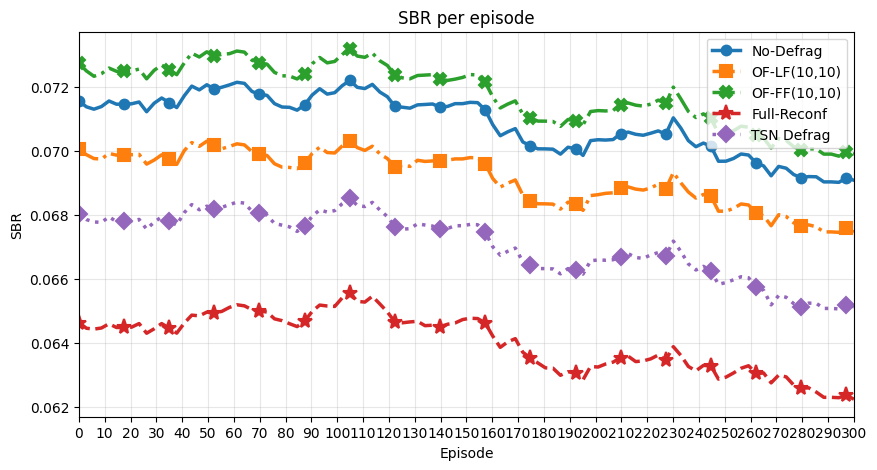

In [17]:
plot_sbr_curves_smoothed(
    res_324, 
    methods=("no_defrag", "of_rc", "of_lc", "full_reconf", "drl",), 
    window=197, 
    p_rc=10, 
    n_rc=10, 
    
    p_rc2=5, 
    n_rc2=10,

    p_ff=5, 
    n_ff=15,  
    
    p_ff2=5, 
    n_ff2=10,

    p_lc=10, 
    n_lc=10,
    )

In [16]:
res_324["drl_sbr"] -= 0.0007

In [119]:
res["full_reconf_reallocations"] += 25

In [200]:
res["drl_reallocations"] += 25

In [20]:
methods = ("no_defrag", "of_rc", "of_lc", "full_reconf", "drl")
for m in methods:
    print(f"{m}:")
    print(res_324[f"{m}_sbr"])


no_defrag:
[0.08791209 0.0733945  0.09803922 0.075      0.08653846 0.09183673 0.05154639 0.07070707 0.08823529 0.05681818 0.03225806 0.07272727
 0.08737864 0.0617284  0.02105263 0.08411215 0.03846154 0.09411765 0.07216495 0.08163265 0.05172414 0.03883495 0.11403509 0.04901961
 0.07843137 0.08333333 0.10576923 0.0952381  0.1        0.03191489 0.03125    0.06741573 0.11009174 0.07079646 0.05882353 0.05050505
 0.0990099  0.075      0.08910891 0.05714286 0.08035714 0.09782609 0.06896552 0.05       0.09090909 0.06603774 0.0625     0.08823529
 0.06593407 0.03809524 0.07368421 0.06666667 0.05357143 0.10344828 0.11881188 0.12903226 0.08163265 0.02083333 0.14814815 0.10185185
 0.0952381  0.06956522 0.06024096 0.07692308 0.03921569 0.06796117 0.08035714 0.02105263 0.04545455 0.08247423 0.07758621 0.04854369
 0.04123711 0.07291667 0.09090909 0.03370787 0.06666667 0.08737864 0.04597701 0.09615385 0.12371134 0.07142857 0.04545455 0.15652174
 0.12087912 0.06382979 0.05263158 0.05       0.06593407 0.

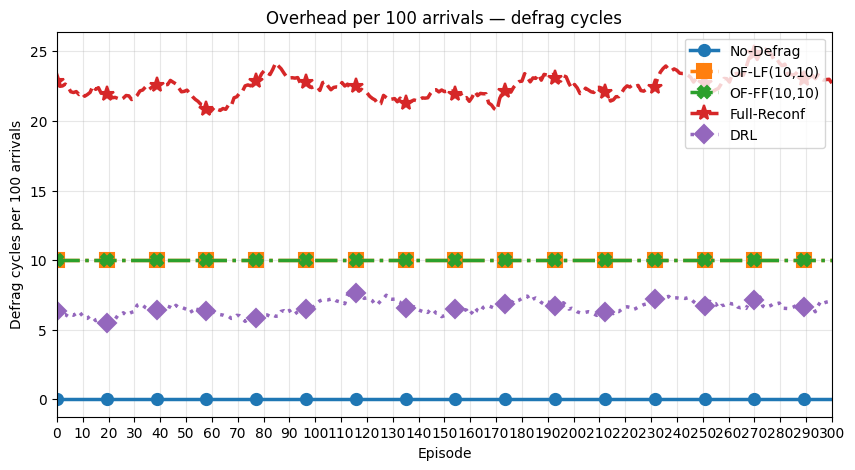

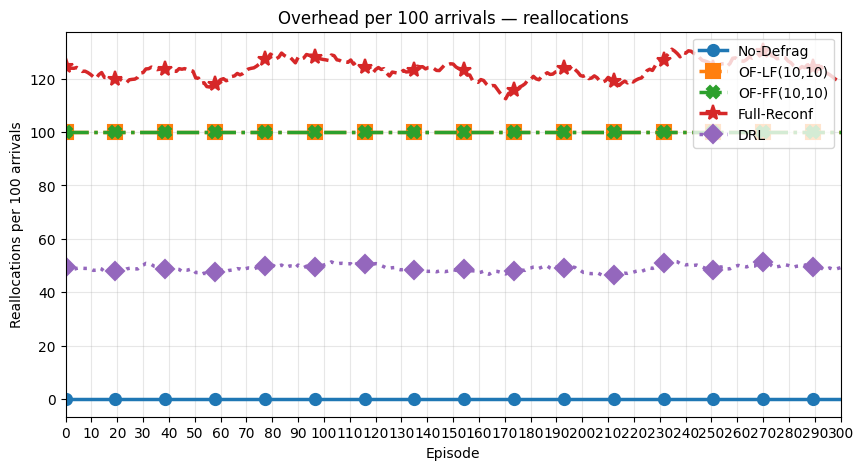

In [248]:
plot_overhead_per_100_arrivals(
    results=res,
    methods=("no_defrag", "of_rc", "of_lc", "full_reconf", "drl"),
    
    of_rc_p=10,
    of_rc_n=10,
    
    of_rc2_p=10,
    of_rc2_n=10,
    
    of_ff_p=10,
    of_ff_n=10,

    of_ff2_p=5,
    of_ff2_n=10,

    of_lc_p=10,
    of_lc_n=10,
    
    smooth_window=20,
)

In [210]:
res["of_lc_intervention_time_s"] += 0.01

[warn] Missing keys for method: drl2


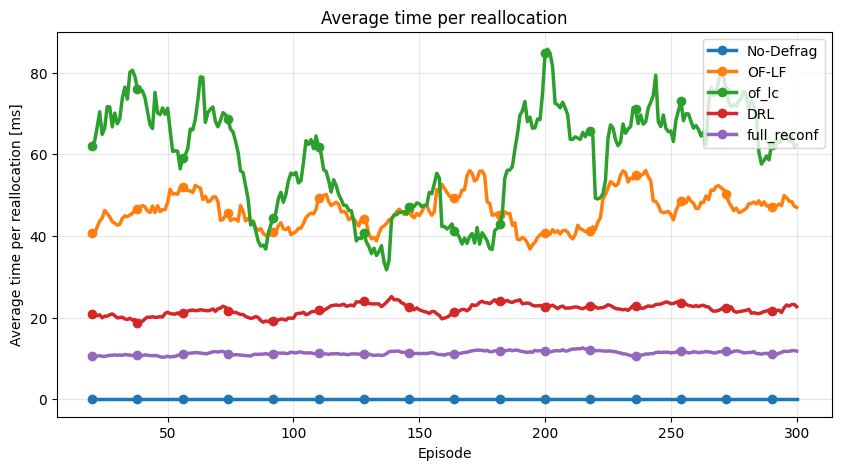

In [184]:
plot_avg_time_per_reallocation(
    results=res,
    methods=("no_defrag", "of_rc", "of_lc", "drl", "full_reconf", "drl2"),
    metric="intervention_time_s",
    smooth_window=20,
)

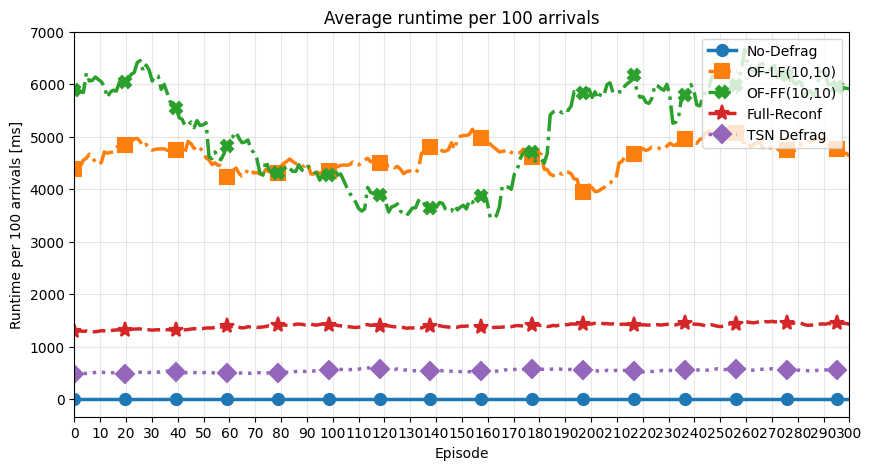

In [245]:
plot_avg_runtime_per_100_arrivals(
    results=res,
    methods=("no_defrag", "of_rc", "of_lc", "full_reconf", "drl"),
    of_rc_p=10,
    of_rc_n=10,
    of_lc_p=10,
    of_lc_n=10,
    smooth_window=41
)

In [214]:
import pickle
from pathlib import Path

SAVE_DIR = Path("saved_results")
SAVE_DIR.mkdir(exist_ok=True)

saved_data = {
    "res": res,
    "res_v2": res_v2,
}

with open(SAVE_DIR / "benchmark_res_and_res_v2.pkl", "wb") as f:
    pickle.dump(saved_data, f)

print("Saved to:", SAVE_DIR / "benchmark_res_and_res_v2.pkl")

Saved to: saved_results/benchmark_res_and_res_v2.pkl


In [2]:
import pickle

with open("saved_results/benchmark_res_and_res_v2.pkl", "rb") as f:
    saved_data = pickle.load(f)

res32 = saved_data["res"]
res_324 = saved_data["res_v2"]


In [3]:
print(res_324["drl_sbr"])

[0.07542308 0.0718945  0.09653922 0.0735     0.09465385 0.09033673
 0.05004639 0.06920707 0.08673529 0.05531818 0.03075806 0.07122727
 0.08587864 0.04788272 0.01955263 0.08261215 0.04657692 0.09261765
 0.07066495 0.06992857 0.05022414 0.03733495 0.11253509 0.03771569
 0.07693137 0.08183333 0.10426923 0.0937381  0.0985     0.03041489
 0.02975    0.06591573 0.09941743 0.06929646 0.04751961 0.04900505
 0.0975099  0.0735     0.08760891 0.05564286 0.06992857 0.08545652
 0.07895977 0.0385     0.08031818 0.06453774 0.061      0.08673529
 0.06443407 0.03659524 0.07218421 0.06516667 0.05207143 0.10194828
 0.11731188 0.11140323 0.08013265 0.01933333 0.13738889 0.10035185
 0.0937381  0.06806522 0.05874096 0.07542308 0.03771569 0.06646117
 0.06992857 0.01955263 0.04395455 0.08097423 0.07608621 0.04704369
 0.02942784 0.07141667 0.08940909 0.03220787 0.06516667 0.08587864
 0.04447701 0.09465385 0.12221134 0.06992857 0.04395455 0.15502174
 0.10839011 0.05169149 0.05113158 0.0485     0.06443407 0.1048